# Accessing particle output

This assumes that ``sust_p`` and ``sust_id`` selections were made in the input namelist file:

### Directories

Adjust this to your case:

In [1]:
top='C:/cygwin64/home/codes/dispatch2/'
experiment='experiments/dust/settling/'

In [2]:
experiment='experiments/dust/settling/'

This should not need to be changed:

In [2]:
import os
os.chdir(top+experiment+'python')

### Python modules

In [3]:
%pylab inline

Populating the interactive namespace from numpy and matplotlib


In [4]:
import sys
sys.path.append(top+'utilities/python')

In [5]:
import dispatch as dis

### Snapshot and variables

In [6]:
sn=dis.snapshot(0)
p=sn.patches[0]

The ``dust_p`` variable has dimension ``[n_bin,4,n_particle]``, where the 1stt slot is particle bin, th 2nd slot is [x,y,z,w] = coordinates and weight, and the last slot particles

In [7]:
f=p.var('dust_p')
w=f[3,:]
s=f[4,:]
r=f[0:3,:]
r.shape,w.shape

((3, 460), (460,))

Size distribution:

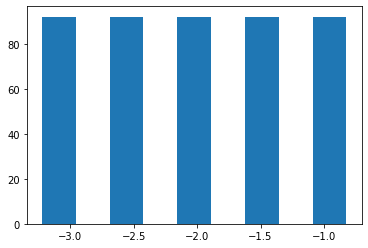

In [8]:
hist(log10(s),bins=9);

Plotting the x-z coordinates of all particles:

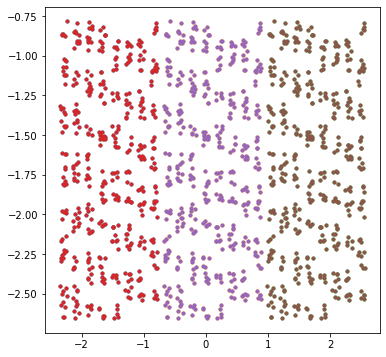

In [10]:
figure(figsize=(6,6))
for p in sn.patches:
    r=p.var('dust_p')
    plot(r[0],r[2],'.')

### Particle IDs

If written out, the ``dust_id`` array holds particle IDs -- these may be useful to track the samme particles from one snapshot to another.

In [9]:
id=p.var('dust_id')
id.shape

(460,)

As particles move from patch to patch, a given particle ID does not keep the same place in the particle list:

In [11]:
sn=dis.snapshot(0)
p=sn.patches[0]
ids=p.var('dust_id')
id=ids[400]
print(id)
for i in range(5):
    sn=dis.snapshot(i)
    for p in sn.patches:
        ids=p.var('dust_id')
        if id in ids:
            print(i,p.id,id,ids[400])

404996
0 1 404996 404996
1 1 404996 404996
2 1 404996 404997
3 1 404996 404997
4 1 404996 404998
